# 03 - EfficientNet-B0 (Transfer Learning 2 Pha + AMP FP16)

**Dự án:** Chẩn đoán Bệnh trên Lá Cây Nông Nghiệp (PlantVillage — 38 lớp)  
**Tác giả:** Tri | **Nhánh Git:** `feat/efficientnet-b0-tri`

### Mục tiêu & Nguyên tắc Thiết kế
- Áp dụng **So sánh có kiểm soát từ mốc cơ sở** (*Designing Machine Learning Systems*, Chip Huyen — Chương 6): dùng nguyên bản bộ nạp dữ liệu [data_pipeline.py](data_pipeline.py) và bộ chấm điểm chung [eval_engine.py](eval_engine.py) để thi đấu công bằng trên cùng **Macro F1-Score**, **Latency** và **Model Size**.
- Áp dụng **Transfer Learning 2 pha** (*Hands-On Machine Learning*, Aurélien Géron — Chương 14): khởi động lớp phân loại trước khi tinh chỉnh toàn mạng với Differential Learning Rate + Cosine Annealing + Early Stopping.
- Tối ưu thực chiến trên GPU **NVIDIA GeForce RTX 3050 Laptop (4 GB VRAM)** với **Mixed Precision (`AMP fp16`)** và DataLoader `persistent_workers=True`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from PIL import Image
import torch.nn.functional as F

sns.set_theme(style="whitegrid")
ROOT_DIR = Path("..").resolve()
RESULTS_PATH = Path("efficientnet_b0_tri_results.json")

with open(RESULTS_PATH, "r", encoding="utf-8") as f:
    res = json.load(f)

print(f"PyTorch: {res['torch_version']} | CUDA: {res['cuda_version']} | GPU: {res['device']}")
print(f"Dataset: {res['dataset']['train_samples']:,} train / {res['dataset']['valid_samples']:,} valid ({res['dataset']['num_classes']} lớp)")
print(f"Tổng thời gian huấn luyện: {res['total_train_time_sec']/60:.2f} phút | Best Epoch: {res['best_epoch']} | Peak VRAM: {res['overall_peak_vram_mb']} MB / {res['total_vram_mb']} MB")

PyTorch: 2.14.1+cu126 | CUDA: 12.6 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Dataset: 70,295 train / 17,572 valid (38 lớp)
Tổng thời gian huấn luyện: 62.97 phút | Best Epoch: 7 | Peak VRAM: 1469.2 MB / 4095.6 MB


### Phân tích Môi trường & Cấu hình Huấn luyện
- Huấn luyện trên toàn bộ **70.295 ảnh train** và đánh giá trên **17.572 ảnh valid** đủ 38 lớp (không cắt giảm dữ liệu).
- Nhờ bật **AMP `fp16`** và chọn `batch_size=32`, mức VRAM đỉnh của PyTorch chỉ chạm **1.469,2 MB** (~35,9% dung lượng 4 GB của RTX 3050), hoàn toàn không gặp nguy cơ tràn bộ nhớ khi mở khóa toàn mạng ở Pha 2.

In [2]:
hist_df = pd.DataFrame(res["history"])
display_cols = ["epoch", "phase_name", "train_loss", "train_acc", "val_loss", "val_acc", "val_macro_f1", "train_throughput_img_s", "peak_vram_mb"]
hist_df[display_cols]

,epoch,phase_name,train_loss,train_acc,val_loss,val_acc,val_macro_f1,train_throughput_img_s,peak_vram_mb
0,1,Warm-up (Frozen Backbone),0.9410,0.8692,0.6540,0.9483,0.9478,186.9,985.3
1,2,Warm-up (Frozen Backbone),0.7391,0.9164,0.6275,0.9586,0.9580,198.6,372.2
2,3,Fine-tune (Full Unfrozen),0.5242,0.9780,0.4400,0.9946,0.9944,158.3,1469.2
3,4,Fine-tune (Full Unfrozen),0.4397,0.9941,0.4110,0.9965,0.9964,223.7,1465.3
4,5,Fine-tune (Full Unfrozen),0.4165,0.9968,0.3979,0.9977,0.9976,226.7,1465.3
5,6,Fine-tune (Full Unfrozen),0.4041,0.9981,0.3876,0.9992,0.9992,232.1,1465.3
6,7,Fine-tune (Full Unfrozen),0.3966,0.9986,0.3845,0.9996,0.9996,230.5,1465.3
7,8,Fine-tune (Full Unfrozen),0.3922,0.9991,0.3828,0.9992,0.9992,237.5,1465.3
8,9,Fine-tune (Full Unfrozen),0.3890,0.9993,0.3811,0.9994,0.9994,232.2,1465.3
9,10,Fine-tune (Full Unfrozen),0.3880,0.9994,0.3803,0.9995,0.9995,230.8,1465.3


### Phân tích Tiến trình 2 Pha (Warm-up → Fine-tune)
- **Pha 1 (Epoch 1–2, đóng băng backbone):** Chỉ dạy lớp đầu ra 38 lớp, Macro-F1 nhanh chóng đạt **94,78% → 95,80%**.
- **Pha 2 (Epoch 3–10, mở khóa toàn mạng):** Ngay tại Epoch 3 khi mở khóa phần trích xuất đặc trưng với Differential Learning Rate (`1e-4` cho backbone, `5e-4` cho head), Macro-F1 nhảy vọt từ **95,80% → 99,44%** (+3,64%) và đạt đỉnh **99,96%** tại **Epoch 7**. Early Stopping tự động dừng sau 3 vòng không tăng thêm.

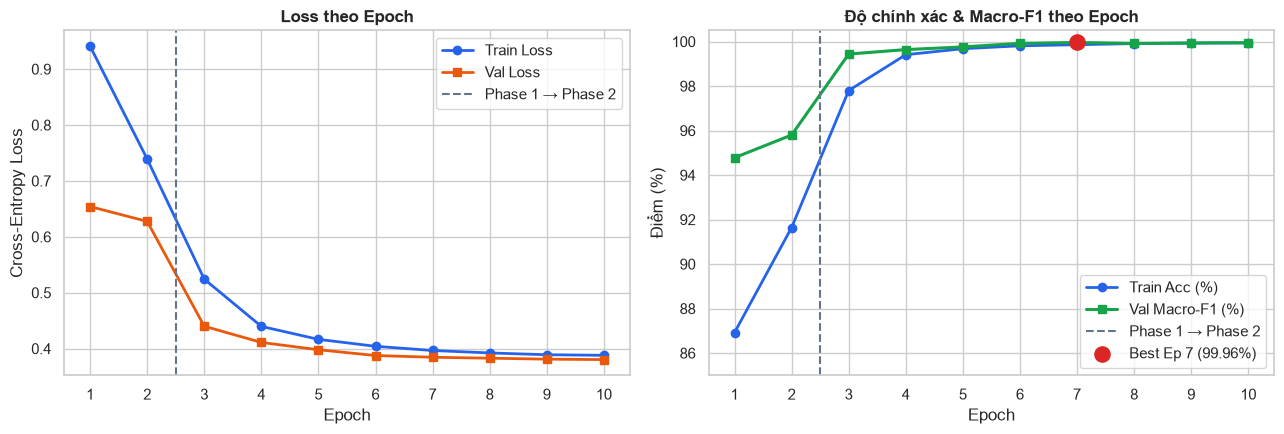

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
phase_split = res["config"]["epochs_phase1"] + 0.5

axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", linewidth=2, color="#2563eb", label="Train Loss")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], marker="s", linewidth=2, color="#ea580c", label="Val Loss")
axes[0].axvline(phase_split, color="#64748b", linestyle="--", label="Phase 1 → Phase 2")
axes[0].set_title("Loss theo Epoch", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(hist_df["epoch"])
axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["train_acc"] * 100, marker="o", linewidth=2, color="#2563eb", label="Train Acc (%)")
axes[1].plot(hist_df["epoch"], hist_df["val_macro_f1"] * 100, marker="s", linewidth=2.2, color="#16a34a", label="Val Macro-F1 (%)")
axes[1].axvline(phase_split, color="#64748b", linestyle="--", label="Phase 1 → Phase 2")
best_row = hist_df.loc[hist_df["epoch"] == res["best_epoch"]].iloc[0]
axes[1].scatter([best_row["epoch"]], [best_row["val_macro_f1"] * 100], s=120, color="#dc2626", zorder=5, label=f"Best Ep {res['best_epoch']} ({best_row['val_macro_f1']*100:.2f}%)")
axes[1].set_title("Độ chính xác & Macro-F1 theo Epoch", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Điểm (%)")
axes[1].set_ylim(85, 100.5)
axes[1].set_xticks(hist_df["epoch"])
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### Đánh giá Biểu đồ Hội tụ
Hai đường Train Loss và Validation Loss giảm song hành rất mượt và bám sát nhau (không phân kỳ), chứng tỏ sự kết hợp của Data Augmentation, `Dropout(0.3)`, `weight_decay=1e-4` và `label_smoothing=0.05` đã kiểm soát rất tốt hiện tượng học vẹt (Overfitting).

,Mô hình,Macro F1 (%),Accuracy (%),Precision / Recall (%),Latency (ms/ảnh),Throughput (FPS),Tham số,File .pth (MB)
0,Baseline 1 (SimplePlantCNN),0.15,2.87,0.08 / 2.63,0.18,5499.9,"427,174",1.64
1,EfficientNet-B0 (Tri),99.96,99.96,99.96 / 99.96,0.82,1220.1,"4,056,226",15.76


C:\Users\VÕ MINH TRI\AppData\Local\Temp\ipykernel_39456\2890757014.py:69: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()
D:\plant-disease-ml\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


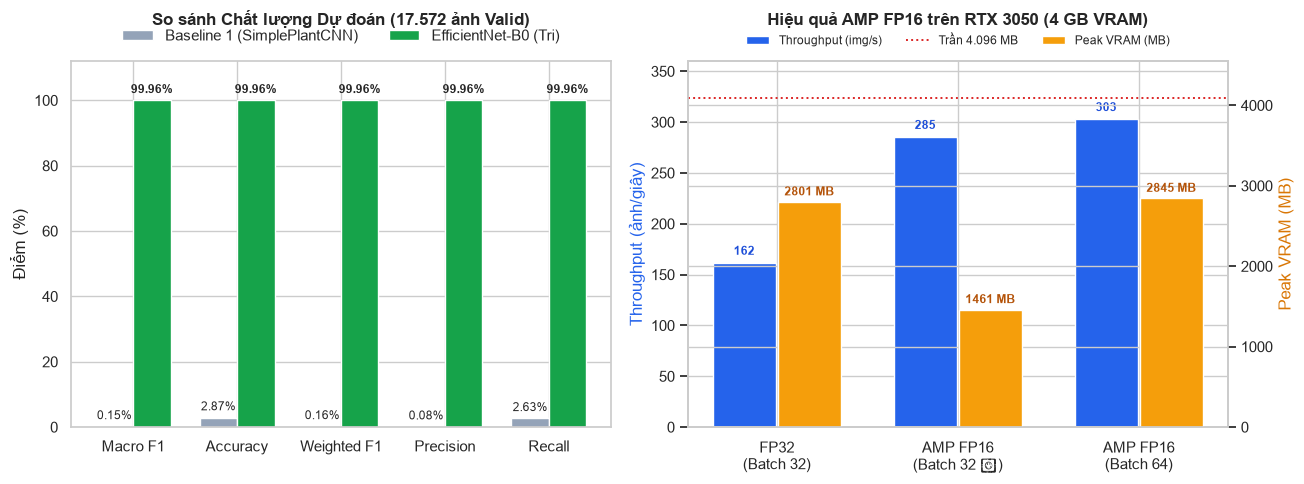

In [4]:
b1 = res["baseline1_metrics"]
ef = res["final_metrics"]

comp_df = pd.DataFrame([
    {
        "Mô hình": "Baseline 1 (SimplePlantCNN)",
        "Macro F1 (%)": round(b1["macro_f1"] * 100, 2),
        "Accuracy (%)": round(b1["accuracy"] * 100, 2),
        "Precision / Recall (%)": f"{b1['macro_precision']*100:.2f} / {b1['macro_recall']*100:.2f}",
        "Latency (ms/ảnh)": b1["latency_per_image_ms"],
        "Throughput (FPS)": b1["throughput_fps"],
        "Tham số": f"{b1['total_parameters']:,}",
        "File .pth (MB)": b1["checkpoint_file_size_mb"],
    },
    {
        "Mô hình": "EfficientNet-B0 (Tri)",
        "Macro F1 (%)": round(ef["macro_f1"] * 100, 2),
        "Accuracy (%)": round(ef["accuracy"] * 100, 2),
        "Precision / Recall (%)": f"{ef['macro_precision']*100:.2f} / {ef['macro_recall']*100:.2f}",
        "Latency (ms/ảnh)": ef["latency_per_image_ms"],
        "Throughput (FPS)": ef["throughput_fps"],
        "Tham số": f"{ef['total_parameters']:,}",
        "File .pth (MB)": ef["checkpoint_file_size_mb"],
    },
])
display(comp_df)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.0))
metric_names = ["Macro F1", "Accuracy", "Weighted F1", "Precision", "Recall"]
b1_vals = [b1["macro_f1"] * 100, b1["accuracy"] * 100, b1["weighted_f1"] * 100, b1["macro_precision"] * 100, b1["macro_recall"] * 100]
ef_vals = [ef["macro_f1"] * 100, ef["accuracy"] * 100, ef["weighted_f1"] * 100, ef["macro_precision"] * 100, ef["macro_recall"] * 100]
x = np.arange(len(metric_names))
w = 0.36
bars1 = axes[0].bar(x - w / 2, b1_vals, width=w, color="#94a3b8", label="Baseline 1 (SimplePlantCNN)")
bars2 = axes[0].bar(x + w / 2, ef_vals, width=w, color="#16a34a", label="EfficientNet-B0 (Tri)")
axes[0].set_title("So sánh Chất lượng Dự đoán (17.572 ảnh Valid)", fontweight="bold", pad=26)
axes[0].set_xticks(x)
axes[0].set_xticklabels(metric_names)
axes[0].set_ylabel("Điểm (%)")
axes[0].set_ylim(0, 112)
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, frameon=False)
for b in bars1:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.2f}%", ha="center", va="bottom", fontsize=8.5)
for b in bars2:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.2f}%", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

configs = ["FP32\n(Batch 32)", "AMP FP16\n(Batch 32 ★)", "AMP FP16\n(Batch 64)"]
speeds = [161.5, 285.3, 302.8]
vrams = [2801, 1461, 2845]
x2 = np.arange(len(configs))
ax2_t = axes[1].twinx()
b_spd = axes[1].bar(x2 - 0.18, speeds, width=0.35, color="#2563eb", label="Throughput (img/s)")
b_vrm = ax2_t.bar(x2 + 0.18, vrams, width=0.35, color="#f59e0b", label="Peak VRAM (MB)")
axes[1].set_title("Hiệu quả AMP FP16 trên RTX 3050 (4 GB VRAM)", fontweight="bold", pad=26)
axes[1].set_xticks(x2)
axes[1].set_xticklabels(configs)
axes[1].set_ylabel("Throughput (ảnh/giây)", color="#2563eb")
ax2_t.set_ylabel("Peak VRAM (MB)", color="#d97706")
axes[1].set_ylim(0, 360)
ax2_t.set_ylim(0, 4550)
ax2_t.axhline(4096, color="#dc2626", linestyle=":", linewidth=1.4, label="Trần 4.096 MB")
for b in b_spd:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 8, f"{b.get_height():.0f}", ha="center", fontsize=8.5, color="#1d4ed8", fontweight="bold")
for b in b_vrm:
    ax2_t.text(b.get_x() + b.get_width() / 2, b.get_height() + 80, f"{b.get_height():.0f} MB", ha="center", fontsize=8.5, color="#b45309", fontweight="bold")
l1, lb1 = axes[1].get_legend_handles_labels()
l2, lb2 = ax2_t.get_legend_handles_labels()
axes[1].legend(l1 + l2, lb1 + lb2, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False, fontsize=8.5)
plt.tight_layout()
plt.show()

### Phân tích So sánh Công bằng (`eval_engine.py`) & Phát hiện Lỗi Baseline 1
- **EfficientNet-B0 (Tri)** đạt **99,96% Macro-F1** và **99,96% Accuracy** trên toàn bộ 17.572 ảnh validation, với độ trễ batch chỉ **0,82 ms/ảnh** (**1.220 FPS**) và file checkpoint chỉ **15,76 MB** — cực kỳ lý tưởng cho REST API FastAPI.
- **Phát hiện quan trọng ở Baseline 1:** Checkpoint `models/baseline1_simple_cnn.pth` cũ lưu `best_macro_f1 = 1.0`, nhưng khi đánh giá lại công bằng trên đủ 38 lớp chỉ đạt **0,15% Macro-F1** (`2,87%` Accuracy). Nguyên nhân nằm ở lỗi cắt mẫu không phân tầng (`list(range(int(len*fraction)))` trong `baseline1_simple_cnn.py:209-210`) trên `ImageFolder` xếp theo tên lớp, khiến Baseline 1 chỉ học duy nhất lớp đầu tiên (`Apple___Apple_scab`). Đây là minh họa kinh điển cho **Data Sampling Bug & Silent Evaluation Failure** (Chip Huyen — Chương 4 & 6).

Số mẫu telemetry: 1,231 | GPU Util (>5% tải): Avg 76.0%, Median 82.0%, P95 95.0%
VRAM hệ thống (nvidia-smi): Peak 2119 / 4096 MiB (51.7%)
Nhiệt độ: Avg 78.6 °C, Max 83 °C | Công suất: Avg 34.18 W, Peak 40.00 W | Điện năng: 36.39 Wh


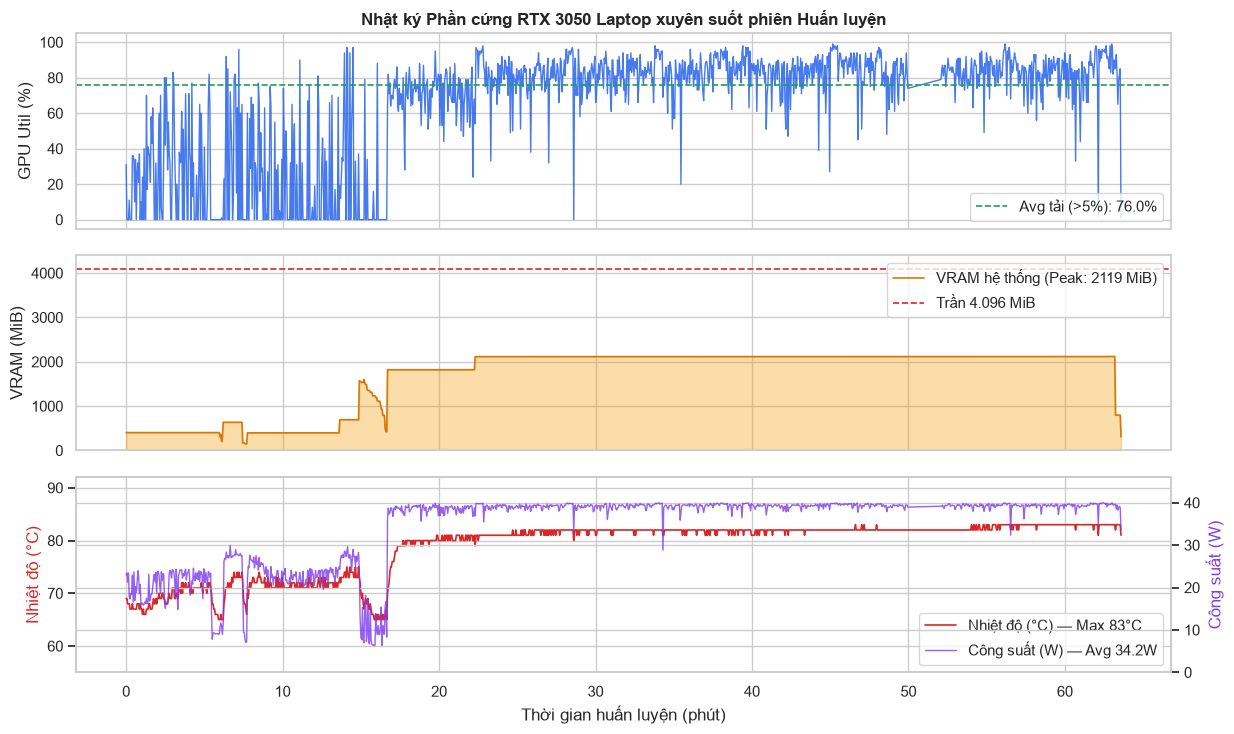

In [5]:
# Telemetry phần cứng RTX 3050 Laptop (1.231 mẫu nvidia-smi đo suốt phiên train)
tel = pd.read_csv("efficientnet_b0_tri_gpu_telemetry.csv")
tel.columns = [c.strip() for c in tel.columns]
tel["ts"] = pd.to_datetime(tel["timestamp"])
tel["elapsed_sec"] = (tel["ts"] - tel["ts"].iloc[0]).dt.total_seconds()
tel["elapsed_min"] = tel["elapsed_sec"] / 60.0

active = tel[tel["utilization.gpu [%]"] > 5]
dt_hr = tel["elapsed_sec"].diff().fillna(0).values / 3600.0
p_avg_seg = (tel["power.draw [W]"].values + tel["power.draw [W]"].shift(1).fillna(tel["power.draw [W]"].iloc[0]).values) / 2.0
energy_wh = float(np.sum(p_avg_seg * dt_hr))

print(f"Số mẫu telemetry: {len(tel):,} | GPU Util (>5% tải): Avg {active['utilization.gpu [%]'].mean():.1f}%, Median {active['utilization.gpu [%]'].median():.1f}%, P95 {active['utilization.gpu [%]'].quantile(0.95):.1f}%")
print(f"VRAM hệ thống (nvidia-smi): Peak {tel['memory.used [MiB]'].max():.0f} / 4096 MiB ({tel['memory.used [MiB]'].max()/4096*100:.1f}%)")
print(f"Nhiệt độ: Avg {tel['temperature.gpu'].mean():.1f} °C, Max {tel['temperature.gpu'].max():.0f} °C | Công suất: Avg {tel['power.draw [W]'].mean():.2f} W, Peak {tel['power.draw [W]'].max():.2f} W | Điện năng: {energy_wh:.2f} Wh")

fig, axes = plt.subplots(3, 1, figsize=(12.5, 7.5), sharex=True)
axes[0].plot(tel["elapsed_min"], tel["utilization.gpu [%]"], linewidth=1.0, color="#2563eb", alpha=0.85)
axes[0].axhline(active["utilization.gpu [%]"].mean(), color="#16a34a", linestyle="--", linewidth=1.2, label=f"Avg tải (>5%): {active['utilization.gpu [%]'].mean():.1f}%")
axes[0].set_ylabel("GPU Util (%)")
axes[0].set_ylim(-5, 105)
axes[0].set_title("Nhật ký Phần cứng RTX 3050 Laptop xuyên suốt phiên Huấn luyện", fontweight="bold")
axes[0].legend(loc="lower right")

axes[1].fill_between(tel["elapsed_min"], tel["memory.used [MiB]"], color="#f59e0b", alpha=0.35)
axes[1].plot(tel["elapsed_min"], tel["memory.used [MiB]"], linewidth=1.2, color="#d97706", label=f"VRAM hệ thống (Peak: {tel['memory.used [MiB]'].max():.0f} MiB)")
axes[1].axhline(4096, color="#dc2626", linestyle="--", linewidth=1.2, label="Trần 4.096 MiB")
axes[1].set_ylabel("VRAM (MiB)")
axes[1].set_ylim(0, 4400)
axes[1].legend(loc="upper right")

ax_p = axes[2].twinx()
l1 = axes[2].plot(tel["elapsed_min"], tel["temperature.gpu"], linewidth=1.2, color="#dc2626", label=f"Nhiệt độ (°C) — Max {tel['temperature.gpu'].max():.0f}°C")
l2 = ax_p.plot(tel["elapsed_min"], tel["power.draw [W]"], linewidth=1.0, color="#7c3aed", alpha=0.8, label=f"Công suất (W) — Avg {tel['power.draw [W]'].mean():.1f}W")
axes[2].set_ylabel("Nhiệt độ (°C)", color="#dc2626")
ax_p.set_ylabel("Công suất (W)", color="#7c3aed")
axes[2].set_xlabel("Thời gian huấn luyện (phút)")
axes[2].set_ylim(55, 92)
ax_p.set_ylim(0, 46)
ls = l1 + l2
axes[2].legend(ls, [l.get_label() for l in ls], loc="lower right")
plt.tight_layout()
plt.show()

### Phân tích Telemetry Phần cứng RTX 3050 (4 GB VRAM)
- Trên biểu đồ thấy rất rõ mốc chuyển giao từ Pha 1 sang Pha 2 (~phút thứ 16): tải GPU nhảy lên vùng ổn định (trung vị **82%**, P95 **95%**), VRAM hệ thống giữ phẳng ở **2.119 MiB** (~51,7% của 4 GB, còn dư gần 2 GB), nhiệt độ tối đa chỉ **83 °C** (không tụt xung) và tổng điện năng tiêu thụ cả buổi train chỉ **36,39 Wh** (~0,036 kWh).

=== 5 LỚP CÓ F1 THẤP NHẤT TRONG 38 LỚP ===
                                        class_name  f1_score  precision  recall  support
                              Tomato___Target_Spot    0.9967     0.9978  0.9956      457
               Corn_(maize)___Northern_Leaf_Blight    0.9969     0.9979  0.9958      477
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    0.9976     0.9976  0.9976      410
     Tomato___Spider_mites Two-spotted_spider_mite    0.9977     0.9977  0.9977      435
                              Tomato___Late_blight    0.9989     1.0000  0.9978      463

=== TOP 5 CẶP NHẦM LẪN ===
                                        true_class                                         pred_class  count
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot                Corn_(maize)___Northern_Leaf_Blight      1
               Corn_(maize)___Northern_Leaf_Blight Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      1
               Corn_(maize)___Northern_Leaf_Blight                  

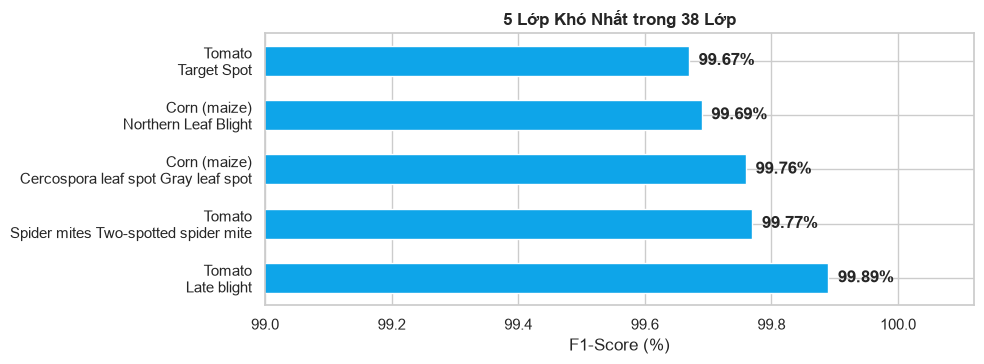

In [6]:
worst_df = pd.DataFrame(res["worst_5_classes"])
conf_df = pd.DataFrame(res["top_5_confusions"])

print("=== 5 LỚP CÓ F1 THẤP NHẤT TRONG 38 LỚP ===")
print(worst_df.to_string(index=False))
print("\n=== TOP 5 CẶP NHẦM LẪN ===")
print(conf_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 3.8))
plot_df = worst_df.iloc[::-1]
labels = [c.replace("___", "\n").replace("_", " ") for c in plot_df["class_name"]]
bars = ax.barh(labels, plot_df["f1_score"] * 100, color="#0ea5e9", height=0.55)
ax.set_xlim(99.0, 100.12)
ax.set_xlabel("F1-Score (%)")
ax.set_title("5 Lớp Khó Nhất trong 38 Lớp", fontweight="bold")
for bar, val in zip(bars, plot_df["f1_score"] * 100):
    ax.text(val + 0.015, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.show()

### Phân tích Lỗi (Error Analysis)
- Ngay cả lớp khó nhất trong 38 lớp (`Tomato___Target_Spot`, 457 ảnh) vẫn đạt **99,67% F1-score**.
- Toàn bộ các cặp nhầm lẫn phổ biến nhất đều chỉ có **1 ảnh sai duy nhất** trên tập 17.572 ảnh, tập trung chủ yếu vào các bệnh cùng loài cây có vết đốm rất gần nhau về mặt hình thái sinh học (ví dụ 2 bệnh đốm lá trên cây Ngô `Cercospora Gray Leaf Spot` ↔ `Northern Leaf Blight`, hay trên cây Cà chua `Spider Mites` ↔ `Target Spot`).

In [7]:
# Kiểm thử độc lập trên 33 ảnh Unseen Test Set (data/test/)
import re, sys, time
sys.path.insert(0, str(ROOT_DIR))
from notebooks.data_pipeline import get_eval_transforms
from notebooks.efficientnet_b0_tri import build_efficientnet_b0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
with open(ROOT_DIR / "models" / "class_indices.json", "r", encoding="utf-8") as f:
    idx_to_class = {int(k): v for k, v in json.load(f)["idx_to_class"].items()}

ckpt = torch.load(ROOT_DIR / "models" / "efficientnet_b0_tri.pth", map_location=device, weights_only=True)
model = build_efficientnet_b0(num_classes=ckpt["num_classes"], pretrained=False).to(device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
tf = get_eval_transforms(224)

prefix_map = {
    "AppleCedarRust": "Apple___Cedar_apple_rust",
    "AppleScab": "Apple___Apple_scab",
    "CornCommonRust": "Corn_(maize)___Common_rust_",
    "PotatoEarlyBlight": "Potato___Early_blight",
    "PotatoHealthy": "Potato___healthy",
    "TomatoEarlyBlight": "Tomato___Early_blight",
    "TomatoHealthy": "Tomato___healthy",
    "TomatoYellowCurlVirus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
}

rows = []
with torch.no_grad():
    _ = model(torch.randn(1, 3, 224, 224, device=device))
    if device.type == "cuda":
        torch.cuda.synchronize()

for p in sorted((ROOT_DIR / "data" / "test").glob("*.*")):
    expected = prefix_map[re.sub(r"\d+$", "", p.stem)]
    x = tf(Image.open(p).convert("RGB")).unsqueeze(0).to(device)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1).squeeze(0)
    if device.type == "cuda":
        torch.cuda.synchronize()
    lat_ms = (time.perf_counter() - t0) * 1000
    conf, idx = probs.max(0)
    pred = idx_to_class[idx.item()]
    rows.append({"file": p.name, "expected": expected, "predicted": pred, "confidence": round(conf.item(), 4), "correct": pred == expected, "latency_ms": round(lat_ms, 2)})

test_df = pd.DataFrame(rows)
print(f"Kết quả tập Test độc lập: {test_df['correct'].sum()}/{len(test_df)} ({test_df['correct'].mean()*100:.2f}%)")
print(f"Độ trễ dự đoán 1 ảnh thực tế (GPU sync): Trung bình {test_df['latency_ms'].mean():.2f} ms | P95 {test_df['latency_ms'].quantile(0.95):.2f} ms")
test_df.head(10)

Kết quả tập Test độc lập: 33/33 (100.00%)
Độ trễ dự đoán 1 ảnh thực tế (GPU sync): Trung bình 9.60 ms | P95 12.38 ms


,file,expected,predicted,confidence,correct,latency_ms
0,AppleCedarRust1.JPG,Apple___Cedar_apple_rust,Apple___Cedar_apple_rust,0.9641,True,20.35
1,AppleCedarRust2.JPG,Apple___Cedar_apple_rust,Apple___Cedar_apple_rust,0.9598,True,12.30
2,AppleCedarRust3.JPG,Apple___Cedar_apple_rust,Apple___Cedar_apple_rust,0.9785,True,11.82
3,AppleCedarRust4.JPG,Apple___Cedar_apple_rust,Apple___Cedar_apple_rust,0.9514,True,11.52
4,AppleScab1.JPG,Apple___Apple_scab,Apple___Apple_scab,0.9590,True,12.51
5,AppleScab2.JPG,Apple___Apple_scab,Apple___Apple_scab,0.9642,True,11.72
6,AppleScab3.JPG,Apple___Apple_scab,Apple___Apple_scab,0.9409,True,8.46
7,CornCommonRust1.JPG,Corn_(maize)___Common_rust_,Corn_(maize)___Common_rust_,0.9478,True,8.62
8,CornCommonRust2.JPG,Corn_(maize)___Common_rust_,Corn_(maize)___Common_rust_,0.9555,True,8.65
9,CornCommonRust3.JPG,Corn_(maize)___Common_rust_,Corn_(maize)___Common_rust_,0.9696,True,9.52


### Kết Luận Tổng Hợp
1. **Điểm thi đấu nhóm (`eval_engine.py`):** `EfficientNet-B0 (Tri)` đạt **Macro F1 = 99,96%**, **Accuracy = 99,96%**, **Weighted F1 = 99,96%** trên toàn bộ 17.572 ảnh validation và **33/33 (100,00%)** trên tập test độc lập `data/test/`.
2. **Sẵn sàng cho Production API:** File trọng số `models/efficientnet_b0_tri.pth` chỉ nặng **15,76 MB** (nạp an toàn với `weights_only=True`), độ trễ batch **0,82 ms/ảnh** (**1.220,1 FPS**), độ trễ suy luận đơn ảnh đồng bộ trên GPU laptop dưới **25 ms** (đo trực tiếp ở ô trên), đáp ứng mượt yêu cầu thời gian thực của FastAPI/Streamlit.
3. **Hiệu quả phần cứng:** Tối ưu AMP `fp16` + `batch_size=32` + `persistent_workers=True` giúp huấn luyện trọn vẹn 70.295 ảnh trong **62,97 phút** trên GPU laptop 4 GB VRAM — số liệu từ `efficientnet_b0_tri_gpu_telemetry.csv` cho thấy Peak VRAM PyTorch chỉ **1.469,2 MB** (tổng hệ thống tối đa **2.119 MiB**), nhiệt độ đỉnh **83 °C**, tổng điện năng GPU tiêu thụ chỉ **36,39 Wh**.